In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    RocCurveDisplay
)

In [5]:
df = pd.read_csv("movies.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Movies:")
print(df[[
    "title", "genres", "release_date", "runtime",
    "budget", "vote_average", "vote_count"
]].head().to_string(index=False))

Dataset Shape: (4803, 24)

Column Names:
['index', 'budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'cast', 'crew', 'director']

First Five Movies:
                                   title                                   genres release_date  runtime    budget  vote_average  vote_count
                                  Avatar Action Adventure Fantasy Science Fiction   2009-12-10    162.0 237000000           7.2       11800
Pirates of the Caribbean: At World's End                 Adventure Fantasy Action   2007-05-19    169.0 300000000           6.9        4500
                                 Spectre                   Action Adventure Crime   2015-10-26    148.0 245000000           6.3        4466
                   The Dark Knight Rises              Action

In [6]:
# Keep movies with at least one vote and a recorded rating
df = df.loc[df["vote_count"].gt(0) & df["vote_average"].notna()].copy()

# Extract the year from dates such as "2009-12-10"
df["release_year"] = pd.to_datetime(
    df["release_date"], errors="coerce"
).dt.year

# Treat zero or negative runtimes and budgets as missing
df["runtime"] = df["runtime"].where(df["runtime"].gt(0))
valid_budget = df["budget"].where(df["budget"].gt(0))

# Use a log scale because movie budgets span a wide range
df["log_budget"] = np.log10(valid_budget)

# 1 = rating >= 7.0, 0 = rating < 7.0
df["highly_rated"] = (df["vote_average"] >= 7.0).astype(int)

class_names = ["Below 7.0", "7.0 or Above"]
class_counts = df["highly_rated"].value_counts().reindex([0, 1])

print("Movies with votes:", len(df))
print("\nRating Class Counts:")
print(class_counts.rename(index=dict(enumerate(class_names))))

Movies with votes: 4741

Rating Class Counts:
highly_rated
Below 7.0       3753
7.0 or Above     988
Name: count, dtype: int64


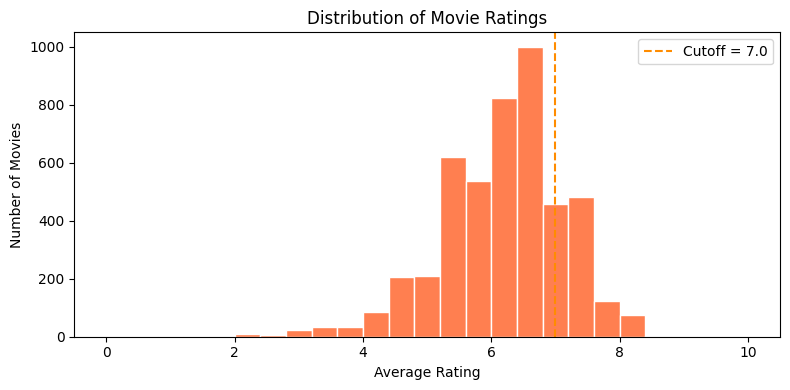

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(df["vote_average"], bins=25, color="coral", edgecolor="white")
ax.axvline(7.0, color="darkorange", linestyle="--", label="Cutoff = 7.0")

ax.set_title("Distribution of Movie Ratings")
ax.set_xlabel("Average Rating")
ax.set_ylabel("Number of Movies")
ax.legend()

plt.tight_layout()
plt.show()

In [8]:
numeric_columns = ["runtime", "release_year", "log_budget"]

X = df[numeric_columns + ["genres"]]
y = df["highly_rated"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Movies:", len(X_train))
print("Testing Movies:", len(X_test))

Training Movies: 3792
Testing Movies: 949


In [9]:
numeric_preprocessor = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

train_numeric = numeric_preprocessor.fit_transform(X_train[numeric_columns])
test_numeric = numeric_preprocessor.transform(X_test[numeric_columns])

def encode_genres(genres):
    cleaned = (
        genres.fillna("")
        .str.replace("Science Fiction", "Science_Fiction", regex=False)
        .str.replace("TV Movie", "TV_Movie", regex=False)
        .str.strip()
    )
    return cleaned.str.get_dummies(sep=" ")

train_genres = encode_genres(X_train["genres"])
test_genres = encode_genres(X_test["genres"]).reindex(
    columns=train_genres.columns,
    fill_value=0
)

X_train_ready = np.column_stack([train_numeric, train_genres.to_numpy()])
X_test_ready = np.column_stack([test_numeric, test_genres.to_numpy()])

print("Processed Training Shape:", X_train_ready.shape)
print("Processed Testing Shape:", X_test_ready.shape)

Processed Training Shape: (3792, 23)
Processed Testing Shape: (949, 23)


In [10]:
model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced"
)

model.fit(X_train_ready, y_train)

y_pred = model.predict(X_test_ready)
decision_scores = model.decision_function(X_test_ready)

print("SVM Training Completed!")
print("First 10 Predictions:", y_pred[:10])

SVM Training Completed!
First 10 Predictions: [1 1 0 0 1 0 0 0 0 0]


In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)
print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred, zero_division=0)
}

print("\nEvaluation Metrics:")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

Confusion Matrix:
[[518 233]
 [ 58 140]]

True Negatives: 518
False Positives: 233
False Negatives: 58
True Positives: 140

Evaluation Metrics:
Accuracy: 0.6934
Balanced Accuracy: 0.6984
Precision: 0.3753
Recall: 0.7071
F1-Score: 0.4904

Classification Report:
              precision    recall  f1-score   support

   Below 7.0       0.90      0.69      0.78       751
7.0 or Above       0.38      0.71      0.49       198

    accuracy                           0.69       949
   macro avg       0.64      0.70      0.64       949
weighted avg       0.79      0.69      0.72       949



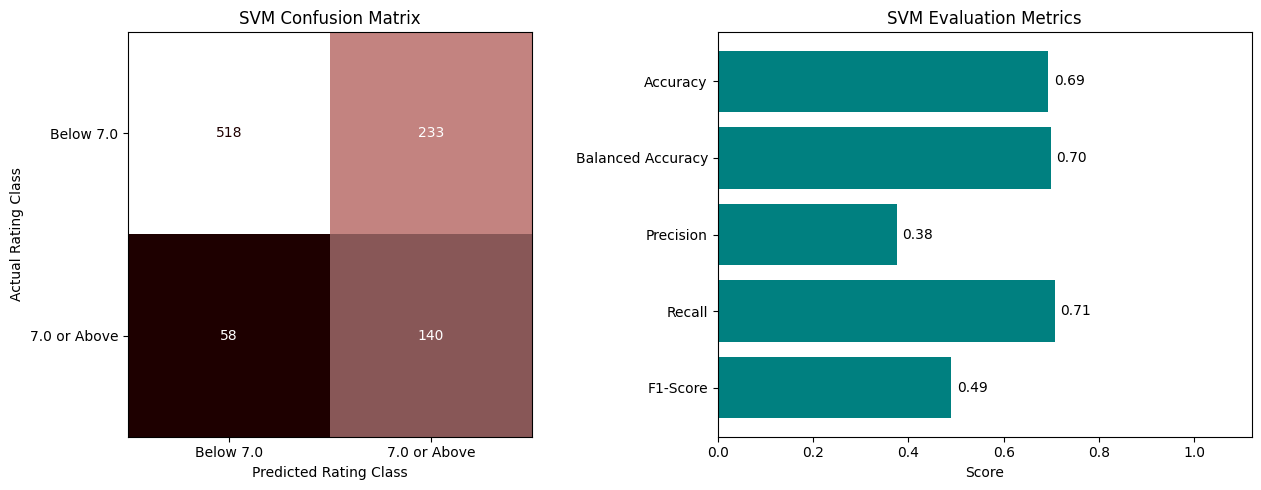

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=axes[0], cmap="pink", values_format="d", colorbar=False)

axes[0].set_title("SVM Confusion Matrix")
axes[0].set_xlabel("Predicted Rating Class")
axes[0].set_ylabel("Actual Rating Class")

bars = axes[1].barh(list(metrics.keys()), list(metrics.values()), color="teal")
axes[1].bar_label(bars, fmt="%.2f", padding=4)
axes[1].set_xlim(0, 1.12)
axes[1].invert_yaxis()
axes[1].set_title("SVM Evaluation Metrics")
axes[1].set_xlabel("Score")

plt.tight_layout()
plt.show()

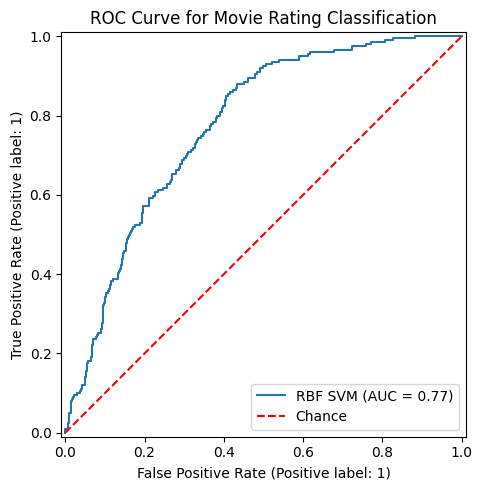

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    decision_scores,
    name="RBF SVM",
    ax=ax
)

ax.plot([0, 1], [0, 1], "--", color="red", label="Chance")
ax.set_title("ROC Curve for Movie Rating Classification")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

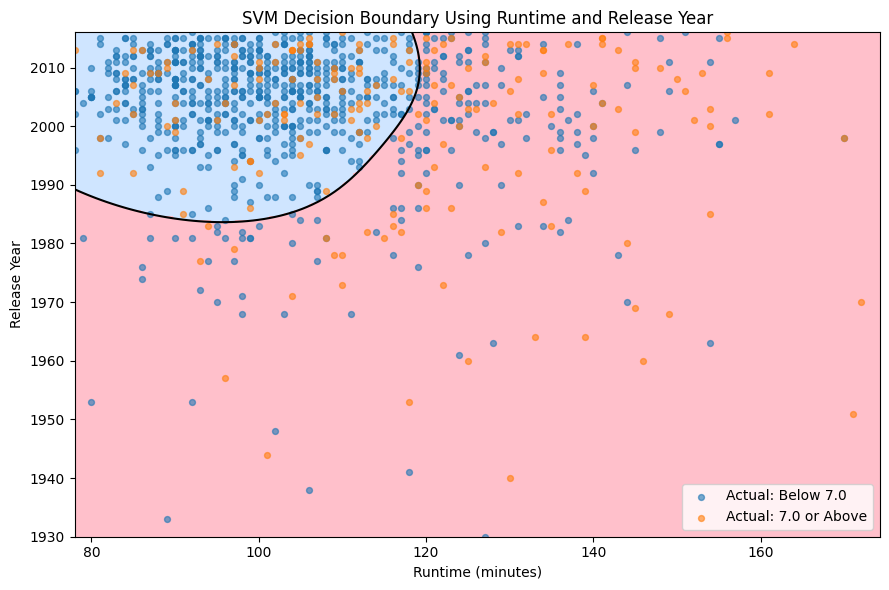

In [24]:
plot_columns = ["runtime", "release_year"]

X_train_plot = X_train[plot_columns]
X_test_plot = X_test[plot_columns].dropna()
y_test_plot = y_test.loc[X_test_plot.index]

plot_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced")
)
plot_model.fit(X_train_plot, y_train)

# Show the central 98% of test runtimes so extreme values don't stretch the plot
runtime_min, runtime_max = X_test_plot["runtime"].quantile([0.01, 0.99])
year_min = X_test_plot["release_year"].min()
year_max = X_test_plot["release_year"].max()

runtime_grid, year_grid = np.meshgrid(
    np.linspace(runtime_min, runtime_max, 150),
    np.linspace(year_min, year_max, 150)
)

grid_points = pd.DataFrame({
    "runtime": runtime_grid.ravel(),
    "release_year": year_grid.ravel()
})
grid_scores = plot_model.decision_function(grid_points).reshape(runtime_grid.shape)

fig, ax = plt.subplots(figsize=(9, 6))

ax.contourf(
    runtime_grid, year_grid, grid_scores >= 0,
    levels=[-0.5, 0.5, 1.5],
    colors=["#cfe5ff", "pink"]
)
ax.contour(
    runtime_grid, year_grid, grid_scores,
    levels=[0], colors="black", linewidths=1.5
)

for label, color in [(0, "tab:blue"), (1, "tab:orange")]:
    movies = X_test_plot.loc[y_test_plot.eq(label)]
    ax.scatter(
        movies["runtime"], movies["release_year"],
        color=color, alpha=0.6, s=18,
        label=f"Actual: {class_names[label]}"
    )

ax.set_xlim(runtime_min, runtime_max)
ax.set_ylim(year_min, year_max)
ax.set_xlabel("Runtime (minutes)")
ax.set_ylabel("Release Year")
ax.set_title("SVM Decision Boundary Using Runtime and Release Year")
ax.legend()

plt.tight_layout()
plt.show()